<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/2%20-%20Regress%C3%A3o%20Linear/2.6_regressao_linear_salarios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 2 — Regressão linear do Dataset da California Housing

## Objetivos

O notebook deve conter:

  1) Uma breve análise dos dados: o que cada variável significa, describe() e um gráfico de dispersão de pelo menos duas variáveis contra o preço.
  2) Divisão em treino, validação e teste (por exemplo 70/15/15, com random_state fixo).
  3) Padronização das entradas e da saída com StandardScaler ajustado só no treino.
  4) Treinamento com nn.Linear(8, 1), nn.MSELoss e optim.SGD, com as curvas de custo de treino e de validação.
  5) RMSE no teste em dólares, comparado com um baseline que sempre prevê o preço médio do treino.
  6) Os 8 pesos aprendidos: quais variáveis mais aumentam e quais mais diminuem o preço previsto? Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas?
  7) Uma conclusão curta: o modelo é bom o suficiente? O que você tentaria para melhorar?

Link: https://scikit-learn.org/0.20/datasets/index.html#california-housing-dataset

Analisar o topico 5.3.7

## Importação das bibliotecas

In [160]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import fetch_california_housing

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

Leitura dos dados

In [161]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target # 20.640 quarteirões, 8 variáveis; y em centenas de milhares de dólares

### Leitura

In [162]:
X.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


In [163]:
y.describe()

,MedHouseVal
count,20640.000000
mean,2.068558
std,1.153956
min,0.149990
25%,1.196000
50%,1.797000
75%,2.647250
max,5.000010


In [164]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB


In [165]:
y.info()

<class 'pandas.core.series.Series'>
RangeIndex: 20640 entries, 0 to 20639
Series name: MedHouseVal
Non-Null Count  Dtype  
--------------  -----  
20640 non-null  float64
dtypes: float64(1)
memory usage: 161.4 KB


O dataset possui um total de 20.640 itens, sendo formado por 8 Parâmetros,  em X:
 - MedInc = Renda Mediana in Quarteirão
 - HouseAge = Idade Mediana das Casas
 - AveRooms = Média de Cômodos
 - AveBedrms = Média de Quartos
 - Population = População no Quarteirão
 - AveOccup = Média de Moradores
 - Latitude = Latitude da casa
 - Longitude = Longitude da Casa

E, em y:
 - MedHouseVal =  Média do Valor da Casa

Não possui dados nullos.

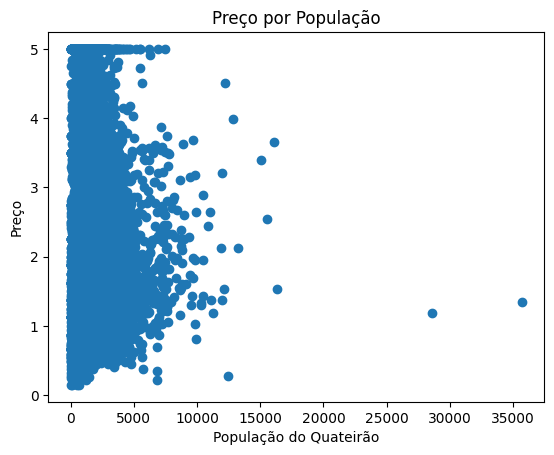

In [166]:
plt.scatter(X['Population'], y)
plt.xlabel('População do Quateirão')
plt.ylabel('Preço')
plt.title('Preço por População')
plt.show()

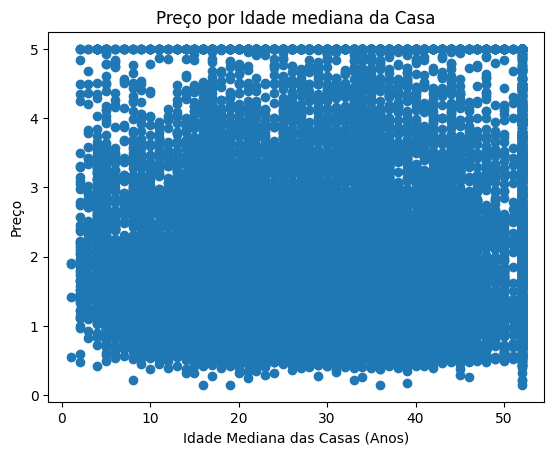

In [167]:
plt.scatter(X['HouseAge'], y)
plt.xlabel('Idade Mediana das Casas (Anos)')
plt.ylabel('Preço')
plt.title('Preço por Idade mediana da Casa')
plt.show()

### Treino × validação

In [168]:
x_raw = X.to_numpy()
y_raw = y.to_numpy().reshape(-1, 1)
x_train_raw, x_temp, y_train_raw, y_temp = train_test_split(
    x_raw, y_raw, test_size=0.3, random_state=42)
x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_temp, y_temp, test_size=0.5, random_state=42)
print(f'Treino: {x_train_raw.shape} | Validação: {x_val_raw.shape} \
| Teste: {x_test_raw.shape}')

Treino: (14448, 8) | Validação: (3096, 8) | Teste: (3096, 8)


### Normalização


In [169]:
x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

# tensores float32 (sem requires_grad: são dados, não parâmetros)
x_train = torch.from_numpy(x_scaler.transform(x_train_raw)).float()
y_train = torch.from_numpy(y_scaler.transform(y_train_raw)).float()
x_val = torch.from_numpy(x_scaler.transform(x_val_raw)).float()
y_val = torch.from_numpy(y_scaler.transform(y_val_raw)).float()

print('x_train:', x_train.shape, ' y_train:', y_train.shape)
print('x_val:  ', x_val.shape, ' y_val:  ', y_val.shape)

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])
x_val:   torch.Size([3096, 8])  y_val:   torch.Size([3096, 1])


## Modelo

`nn.Linear(8, 1)` tem `bias=True` por padrão e calcula $\hat{y} = w_1 x + w_0$:

- `model.weight`, shape (1, 8), é o peso $w_1$;
- `model.bias`, shape (1,), é o bias $w_0$.

Total de 9 parâmetros

In [170]:
model = nn.Linear(8, 1)
print('weight (w1):', model.weight)
print('bias (w0):  ', model.bias)

weight (w1): Parameter containing:
tensor([[-0.3331, -0.0694, -0.1698, -0.0943, -0.3123,  0.1419, -0.3169, -0.0225]],
       requires_grad=True)
bias (w0):   Parameter containing:
tensor([0.1229], requires_grad=True)


### Testando o predict da rede

In [171]:
model(torch.ones(5, 8))

tensor([[-1.0536],
        [-1.0536],
        [-1.0536],
        [-1.0536],
        [-1.0536]], grad_fn=<AddmmBackward0>)

In [172]:
model(x_train[:3])

tensor([[0.3319],
        [0.9249],
        [0.4498]], grad_fn=<AddmmBackward0>)

## Treinamento

### Função de custo e otimizador

Os mesmos das atividades passadas.

In [173]:
lr = 0.3
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)   # atualiza weight e bias

### Funções de treino e de validação

O código de uma época vira duas funções:

- `train_epoch` faz um passo de gradiente descendente com todo o conjunto de treino (as 14.448 amostras de uma vez; aqui uma época é uma iteração. Mini-batches) e devolve o custo;
- `validate_epoch` só calcula o custo na validação, sem atualizar nada.

Duas construções novas:

- `model.train()` e `model.eval()` colocam o modelo em modo de treino ou de avaliação. Para `nn.Linear` não muda nada; muda para camadas como dropout e batch normalization, que se comportam de forma diferente no treino (módulo 4). Usar os dois desde já é o padrão do PyTorch.
- `with torch.no_grad():` desliga o registro do grafo do autograd. Na validação não há `backward()`, então o grafo seria memória e tempo desperdiçados.

In [174]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()            # modo de treino
    optimizer.zero_grad()

    # forward
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)

    # backward e otimizador
    loss.backward()
    optimizer.step()

    return loss.item()       # custo como número Python

In [175]:
def validate_epoch(model, criterion, x_val, y_val):
    model.eval()             # modo de avaliação
    with torch.no_grad():    # sem grafo do autograd: não haverá backward
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

### Laço de treinamento

A cada época: um passo de treino, a medida na validação e o registro dos parâmetros. Observe que `train_loss` é medido no forward, antes do `step()` daquela época, e `val_loss` depois dele.

In [176]:
n_epochs = 300
w0_list = []   # bias
w1_list = []   # pesos
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    w0_list.append(model.bias.item())
    w1_list.append(model.weight.detach().numpy().copy())

    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    train_losses.append(train_loss)

    val_loss = validate_epoch(model, criterion, x_val, y_val)
    val_losses.append(val_loss)

    if (epoch + 1) % 20 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}')

Epoch[20/300], Train Loss: 0.402168, Val Loss: 0.413673
Epoch[40/300], Train Loss: 0.392304, Val Loss: 0.405145
Epoch[60/300], Train Loss: 0.390904, Val Loss: 0.403969
Epoch[80/300], Train Loss: 0.390696, Val Loss: 0.403794
Epoch[100/300], Train Loss: 0.390662, Val Loss: 0.403759
Epoch[120/300], Train Loss: 0.390656, Val Loss: 0.403746
Epoch[140/300], Train Loss: 0.390655, Val Loss: 0.403739
Epoch[160/300], Train Loss: 0.390654, Val Loss: 0.403735
Epoch[180/300], Train Loss: 0.390654, Val Loss: 0.403733
Epoch[200/300], Train Loss: 0.390654, Val Loss: 0.403732
Epoch[220/300], Train Loss: 0.390654, Val Loss: 0.403731
Epoch[240/300], Train Loss: 0.390654, Val Loss: 0.403730
Epoch[260/300], Train Loss: 0.390654, Val Loss: 0.403730
Epoch[280/300], Train Loss: 0.390654, Val Loss: 0.403730
Epoch[300/300], Train Loss: 0.390654, Val Loss: 0.403730


## Avaliação

### Curvas de custo de treino e de validação

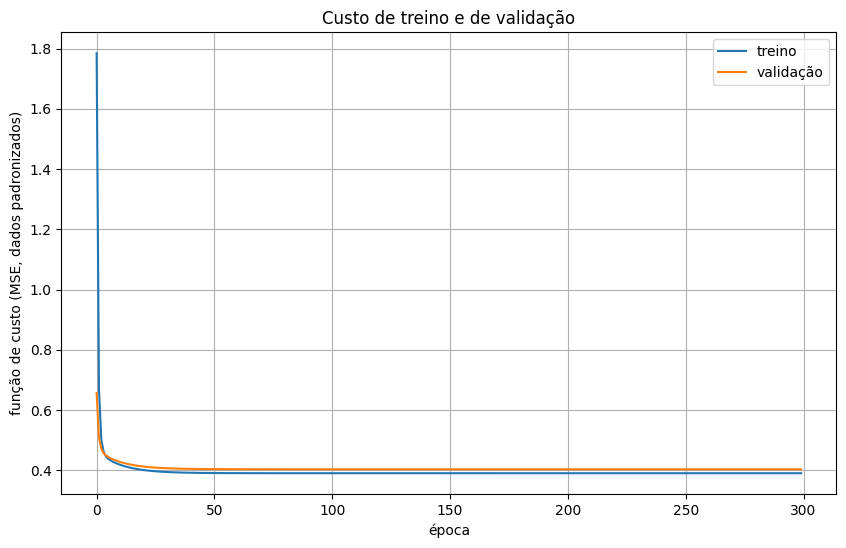

In [177]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label='treino')
plt.plot(range(n_epochs), val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

### Reta ajustada

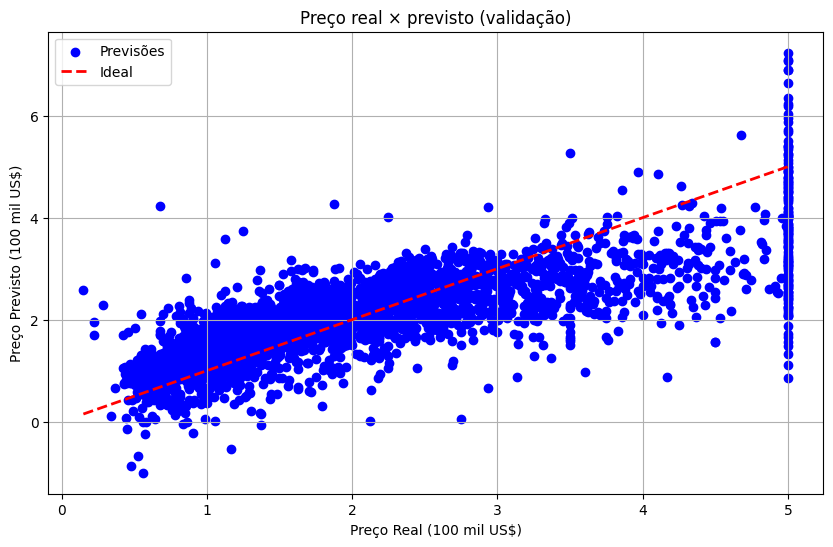

In [178]:
model.eval()
with torch.no_grad():
    y_prev_val = model(x_val)

# Desfaz a padronização das previsões e dos alvos para plotar na escala original
y_prev_val_raw = y_scaler.inverse_transform(y_prev_val.numpy())

plt.figure(figsize=(10, 6))
plt.scatter(y_val_raw, y_prev_val_raw, color='b', label='Previsões')
plt.plot([y_val_raw.min(), y_val_raw.max()], [y_val_raw.min(), y_val_raw.max()], 'r--', lw=2, label='Ideal')
plt.xlabel('Preço Real (100 mil US$)')
plt.ylabel('Preço Previsto (100 mil US$)')
plt.title('Preço real × previsto (validação)')
plt.legend()
plt.grid(True)
plt.show()

### Parâmetros treinados (na escala padronizada)

In [179]:
x_test = torch.from_numpy(x_scaler.transform(x_test_raw)).float()

model.eval()
with torch.no_grad():
    prev = y_scaler.inverse_transform(model(x_test).numpy())

rmse_modelo   = np.sqrt(((prev - y_test_raw)**2).mean()) * 100_000
rmse_baseline = np.sqrt(((y_train_raw.mean() - y_test_raw)**2).mean()) * 100_000
print(f'RMSE modelo:   US$ {rmse_modelo:,.0f}')
print(f'RMSE baseline: US$ {rmse_baseline:,.0f}')

RMSE modelo:   US$ 72,129
RMSE baseline: US$ 114,992


Latitude     -0.772245
Longitude    -0.750440
AveRooms     -0.258822
AveOccup     -0.036026
Population   -0.000764
HouseAge      0.105508
AveBedrms     0.301026
MedInc        0.733706
dtype: float32


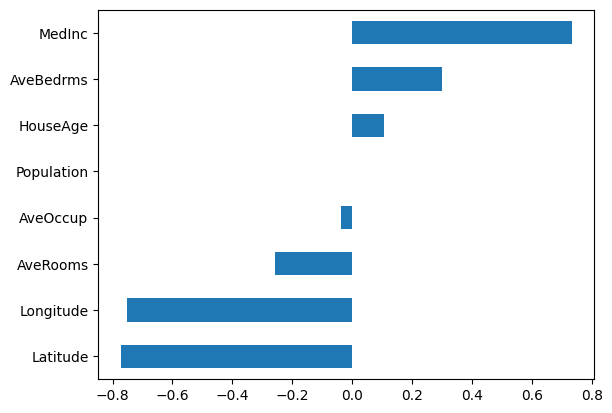

In [180]:
pesos = pd.Series(model.weight.detach().numpy().ravel(), index=X.columns).sort_values()
print(pesos)
pesos.plot.barh()
plt.show()

## Observações

- O dataset não apresentou dados nulos, o que torna não necessária a limpeza dos dados. Apresentando 20.640 quarteirõess e 8 variáveis numérias.
- Podemos observar que o MedInc e AveBedrms são os dados que mais aumentam, e no geral Latitude, Longitude e AveRooms diminuem.




## Conclusões
O modelo é bom o suficiente?
- O modelo tem um custo de `U$ 72.129 Mil`, contam um baseline de `U$ 114.992 mil`, apresentando portanto um ganho real bom.

O que você tentaria para melhorar?
- Realizar uma maior tratativa nos dados;
- Considerar cálculo de distância de locação e clusterizar por região;
- Valor máximo de 5 nos dados de `y`.